In [2]:
import pandas as pd
pd.options.mode.copy_on_write = True

file_path = "antiviral_peptides.xlsx"
df = pd.read_excel(file_path)

In [3]:
df["Connectives"] = df["Connectives"].fillna("").astype(str)

In [4]:
df["Connectives_Split"] = df["Connectives"].str.split(",")
df_exploded = df.explode("Connectives_Split").copy()
df_exploded["Connectives_Split"] = df_exploded["Connectives_Split"].str.strip()
df_exploded["Target"] = df_exploded["Connectives_Split"].str.replace(r'(Anti-)+', '', regex=True)
df_exploded["Target"] = df_exploded["Target"].str.replace(r' ', '-')
df_exploded.drop(columns=["Connectives_Split"], inplace=True)

print(df_exploded[["Connectives", "Target"]].head(15))

                                          Connectives             Target
0                                            Anti-HCV                HCV
1                                            Anti-HCV                HCV
2                                            Anti-HIV                HIV
3                                            Anti-RSV                RSV
4                                            Anti-RSV                RSV
5                                           Anti-EBOV               EBOV
6                                           Anti-EBOV               EBOV
7                         Anti-Anti-Influenza A virus  Influenza-A-virus
8                         Anti-Anti-Influenza A virus  Influenza-A-virus
9   Anti-Anti-Influenza A virus, Anti-Influenza B ...  Influenza-A-virus
9   Anti-Anti-Influenza A virus, Anti-Influenza B ...  Influenza-B-virus
9   Anti-Anti-Influenza A virus, Anti-Influenza B ...         SARS-CoV-2
10                        Anti-Anti-Influenza A vir

In [5]:
df_exploded.columns

Index(['DRAVP_ID', 'Sequence', 'Sequence_Length', 'Name', 'Source',
       'Uniprot_ID', 'PDB_ID', 'Target_Organism', 'Family', 'Assay',
       'Activity', 'Hemolytic_Activity', 'Cytotoxicity_Activity',
       'Predicted_structure_ID', 'Structure', 'Linear_Cyclic',
       'N-terminal_Modification', 'C-terminal_Modification',
       'Other_Modification', 'Stereochemistry', 'Binding_Target', 'Mechanism',
       'Mass', 'Formula', 'Absent_amino_acids', 'Common_amino_acids', 'pI',
       'Basic_residues', 'Acidic_residues', 'Net_charge', 'Polar_residues',
       'Hydrophobic_residues', 'Hydrophobicity', 'Boman_Index',
       'Half_Life_Mammalian_', 'Half_Life__Yeast_', 'Half_Life__E_coli_',
       'Aliphatic_Index', 'Extinction_Coefficient_cystines',
       'Absorbance_280nm', 'Pubmed_ID', 'Reference', 'Author', 'Title', 'Doi',
       'Other_link', 'Connectives', 'Target'],
      dtype='object')

In [6]:
df_req = df_exploded[['Sequence','Sequence_Length','Source','Family','pI','Basic_residues','Acidic_residues','Net_charge','Polar_residues','Hydrophobic_residues','Hydrophobicity','Boman_Index','Aliphatic_Index','Extinction_Coefficient_cystines','Target']]
df_req

,Sequence,Sequence_Length,Source,Family,pI,Basic_residues,Acidic_residues,Net_charge,Polar_residues,Hydrophobic_residues,Hydrophobicity,Boman_Index,Aliphatic_Index,Extinction_Coefficient_cystines,Target
0,IFKAIWSGIKSLF,13,Heterometrus petersii,Flaviviridae,10.00,2,0,2,3,8,107.69,1282,127.69,5500,HCV
1,GFGCPFNQGKCHRHCRSIRRRGGYCDGFLKQRCVCYRK,38,Mesobuthus martensii Karsch,Flaviviridae,10.00,12,1,11,16,6,-92.37,-12439,28.16,3355,HCV
2,FIKRIARLLRKIF,13,Synthetic construct(derived from BmKn2),Retroviridae,12.31,5,0,5,0,8,55.38,-2349,157.69,0,HIV
3,MITHGCYTRTRHKHKLKKTL,20,Synthetic construct,Paramyxoviridae,10.58,9,0,9,7,3,-111.00,-5711,58.50,1490,RSV
4,KRRGGGKLLKLLLKLLLKLLKC,22,Synthetic construct,Paramyxoviridae,11.27,8,0,8,4,10,31.36,-984,177.27,0,RSV
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1981,QDKHEEDYQMYNKGDKED,18,Synthetic construct,Coronaviridae,4.38,4,7,-3,4,0,-283.33,-9133,0.00,2980,SARS-CoV-2
1982,DKFNHEAEDLFYQSSLASWNYNT,23,Synthetic construct,Coronaviridae,4.31,2,4,-2,9,7,-108.26,-5803,42.61,8480,SARS-CoV-2
1983,IDENARSYIDKFQHDAEEMWYQ,22,Synthetic construct,Coronaviridae,4.29,3,6,-3,4,6,-136.82,-7200,44.55,8480,SARS-CoV-2
1984,IYALLENAEDYNLVN,15,Synthetic construct,Coronaviridae,3.57,0,3,-3,5,7,0.67,-1520,136.67,2980,SARS-CoV-2


In [7]:
df_req.isnull().sum()

Sequence                           0
Sequence_Length                    0
Source                             1
Family                             5
pI                                 0
Basic_residues                     0
Acidic_residues                    0
Net_charge                         0
Polar_residues                     0
Hydrophobic_residues               0
Hydrophobicity                     0
Boman_Index                        0
Aliphatic_Index                    0
Extinction_Coefficient_cystines    0
Target                             0
dtype: int64

In [8]:
df_req.dropna(inplace=True)

In [9]:
df_req.to_csv('dataset.csv',index=False)

In [10]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
import joblib

In [11]:
file_path_new = "dataset.csv"
new_df = pd.read_csv(file_path_new)

In [12]:
label_encoder_source = LabelEncoder()
label_encoder_family = LabelEncoder()
label_encoder_target = LabelEncoder()

new_df['Source_encoded'] = label_encoder_source.fit_transform(new_df['Source'])
new_df['Family_encoded'] = label_encoder_family.fit_transform(new_df['Family'])
new_df['Target_encoded'] = label_encoder_target.fit_transform(new_df['Target'])
new_df.drop(columns=['Source','Family','Target'], inplace=True)

joblib.dump(label_encoder_source, 'label_encoder_source.pkl')
joblib.dump(label_encoder_family, 'label_encoder_family.pkl')
joblib.dump(label_encoder_target, 'label_encoder_target.pkl')

['label_encoder_target.pkl']

In [13]:
scaler = StandardScaler()
numerical_columns = ['Sequence_Length', 'pI', 'Basic_residues', 'Acidic_residues', 
                     'Net_charge', 'Polar_residues', 'Hydrophobic_residues', 'Hydrophobicity',
                     'Boman_Index', 'Aliphatic_Index', 'Extinction_Coefficient_cystines']

new_df[numerical_columns] = scaler.fit_transform(new_df[numerical_columns])

joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']

In [14]:
new_df

,Sequence,Sequence_Length,pI,Basic_residues,Acidic_residues,Net_charge,Polar_residues,Hydrophobic_residues,Hydrophobicity,Boman_Index,Aliphatic_Index,Extinction_Coefficient_cystines,Source_encoded,Family_encoded,Target_encoded
0,IFKAIWSGIKSLF,-0.737899,0.888993,-0.563747,-0.819963,0.305606,-0.463397,0.000199,1.375658,1.143398,0.812378,0.137739,21,14,21
1,GFGCPFNQGKCHRHCRSIRRRGGYCDGFLKQRCVCYRK,1.504950,0.888993,2.907059,-0.519908,2.786950,2.920768,-0.466198,-0.705242,-2.070539,-1.511835,-0.222489,43,14,21
2,FIKRIARLLRKIF,-0.737899,1.665777,0.477495,-0.819963,1.132721,-1.244358,0.000199,0.831562,0.292891,1.512934,-0.785922,79,40,26
3,MITHGCYTRTRHKHKLKKTL,-0.109902,1.084030,1.865817,-0.819963,2.235540,0.577885,-1.165795,-0.899019,-0.494607,-0.803339,-0.535694,73,36,56
4,KRRGGGKLLKLLLKLLLKLLKC,0.069526,1.316056,1.518737,-0.819963,1.959835,-0.203077,0.466597,0.581721,0.612622,1.970164,-0.785922,73,36,56
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2337,QDKHEEDYQMYNKGDKED,-0.289329,-1.000846,0.130415,1.280423,-1.072918,-0.203077,-1.865391,-2.691489,-1.296159,-2.169424,-0.285466,73,4,59
2338,DKFNHEAEDLFYQSSLASWNYNT,0.159240,-1.024385,-0.563747,0.380258,-0.797213,1.098525,-0.233000,-0.870520,-0.516156,-1.174401,0.638195,73,4,59
2339,IDENARSYIDKFQHDAEEMWYQ,0.069526,-1.031111,-0.216666,0.980368,-1.072918,-0.203077,-0.466198,-1.167583,-0.843383,-1.129098,0.638195,73,4,59
2340,IYALLENAEDYNLVN,-0.558471,-1.273225,-1.257908,0.080203,-1.072918,0.057244,-0.233000,0.262503,0.487072,1.022077,-0.285466,73,4,59


In [15]:
tfidf_vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(1, 3), max_features=500)
X_sequence_tfidf = tfidf_vectorizer.fit_transform(new_df['Sequence'])

joblib.dump(tfidf_vectorizer, 'tfidf_vectorizer.pkl')

['tfidf_vectorizer.pkl']

In [16]:
X_sequence_df = pd.DataFrame(X_sequence_tfidf.toarray(), columns=tfidf_vectorizer.get_feature_names_out())
new_df = new_df.join(X_sequence_df)
new_df.drop(columns=['Sequence'],inplace=True)

new_df.to_csv("preprocessed_dataset.csv", index=False)

In [17]:
new_df.isnull().sum().unique()

array([0], dtype=int64)

In [18]:
new_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2342 entries, 0 to 2341
Columns: 514 entries, Sequence_Length to yvl
dtypes: float64(511), int32(3)
memory usage: 9.2 MB


c:\Users\dipen\OneDrive\Desktop\Qriocity\venv\lib\site-packages\stable_baselines3\common\vec_env\patch_gym.py:49: UserWarning: You provided an OpenAI Gym environment. We strongly recommend transitioning to Gymnasium environments. Stable-Baselines3 is automatically wrapping your environments in a compatibility layer, which could potentially cause issues.
  warnings.warn(
c:\Users\dipen\OneDrive\Desktop\Qriocity\venv\lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


**************************************************
Training PPO
Step: 10000, Reward: -439, Accuracy: 0.031982942430703626
Step: 20000, Reward: -411, Accuracy: 0.06183368869936034
Step: 30000, Reward: -341, Accuracy: 0.13646055437100213
Step: 40000, Reward: -153, Accuracy: 0.3368869936034115
Step: 50000, Reward: -73, Accuracy: 0.42217484008528783
Step: 60000, Reward: -39, Accuracy: 0.4584221748400853
Step: 70000, Reward: -21, Accuracy: 0.47761194029850745
Step: 80000, Reward: 3, Accuracy: 0.5031982942430704
Step: 90000, Reward: -3, Accuracy: 0.4968017057569296
Step: 100000, Reward: 1, Accuracy: 0.5010660980810234
**************************************************
PPO Training Ended
**************************************************
Training A2C


c:\Users\dipen\OneDrive\Desktop\Qriocity\venv\lib\site-packages\stable_baselines3\common\vec_env\patch_gym.py:49: UserWarning: You provided an OpenAI Gym environment. We strongly recommend transitioning to Gymnasium environments. Stable-Baselines3 is automatically wrapping your environments in a compatibility layer, which could potentially cause issues.
  warnings.warn(
c:\Users\dipen\OneDrive\Desktop\Qriocity\venv\lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run A2C on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


Step: 10000, Reward: -121, Accuracy: 0.37100213219616207
Step: 20000, Reward: -121, Accuracy: 0.37100213219616207
Step: 30000, Reward: -121, Accuracy: 0.37100213219616207
Step: 40000, Reward: -121, Accuracy: 0.37100213219616207
Step: 50000, Reward: -121, Accuracy: 0.37100213219616207
Step: 60000, Reward: -121, Accuracy: 0.37100213219616207
Step: 70000, Reward: -121, Accuracy: 0.37100213219616207
Step: 80000, Reward: -123, Accuracy: 0.36886993603411516
Step: 90000, Reward: -121, Accuracy: 0.37100213219616207
Step: 100000, Reward: -121, Accuracy: 0.37100213219616207
**************************************************
A2C Training Ended
**************************************************
Training DQN


c:\Users\dipen\OneDrive\Desktop\Qriocity\venv\lib\site-packages\stable_baselines3\common\vec_env\patch_gym.py:49: UserWarning: You provided an OpenAI Gym environment. We strongly recommend transitioning to Gymnasium environments. Stable-Baselines3 is automatically wrapping your environments in a compatibility layer, which could potentially cause issues.
  warnings.warn(


Step: 10000, Reward: -5, Accuracy: 0.4946695095948827
Step: 20000, Reward: 3, Accuracy: 0.5031982942430704
Step: 30000, Reward: 15, Accuracy: 0.5159914712153518
Step: 40000, Reward: 21, Accuracy: 0.5223880597014925
Step: 50000, Reward: 31, Accuracy: 0.5330490405117271
Step: 60000, Reward: 59, Accuracy: 0.5628997867803838
Step: 70000, Reward: 55, Accuracy: 0.55863539445629
Step: 80000, Reward: 63, Accuracy: 0.5671641791044776
Step: 90000, Reward: 67, Accuracy: 0.5714285714285714
Step: 100000, Reward: 61, Accuracy: 0.5650319829424307
**************************************************
DQN Training Ended


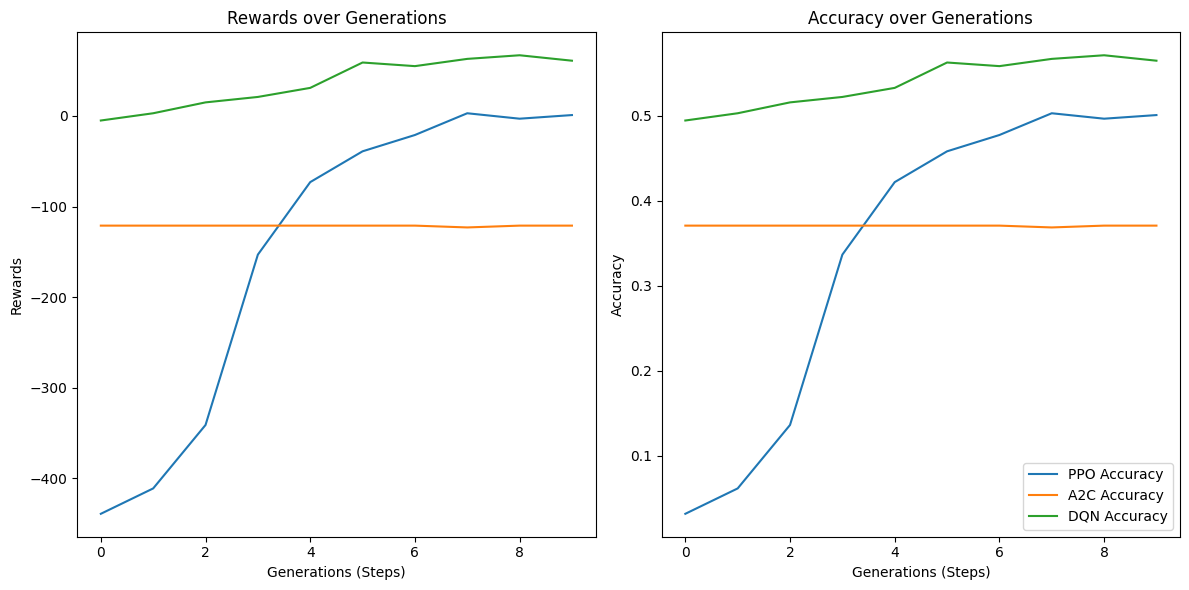

In [18]:
import gym
from gym import spaces
import numpy as np
from stable_baselines3 import PPO, A2C, DQN
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from stable_baselines3.common.callbacks import BaseCallback
from sklearn.model_selection import train_test_split

X = new_df.drop(columns=['Target_encoded'])
y = new_df['Target_encoded']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

class SupervisedLearningEnv(gym.Env):
    def __init__(self, X, y):
        super(SupervisedLearningEnv, self).__init__()
        self.X = X
        self.y = y
        self.current_step = 0
        self.action_space = spaces.Discrete(len(np.unique(y)))  
        self.observation_space = spaces.Box(low=0, high=1, shape=(X.shape[1],), dtype=np.float32)

    def reset(self):
        self.current_step = 0
        return self.X.iloc[self.current_step].values

    def step(self, action):
        done = False
        reward = 0
        correct_action = int(self.y.iloc[self.current_step])

        if action == correct_action:
            reward = 1
        else:
            reward = -1
        
        self.current_step += 1
        if self.current_step >= len(self.X):
            done = True
            self.current_step = 0  
        next_state = self.X.iloc[self.current_step].values if not done else None
        
        return next_state, reward, done, {}

class TrackMetricsCallback(BaseCallback):
    def __init__(self, eval_env, verbose=1):
        super(TrackMetricsCallback, self).__init__(verbose)
        self.eval_env = eval_env
        self.rewards = []
        self.accuracy = []
    
    def _on_step(self):
        if self.n_calls % 10000 == 0: 
            total_reward = 0
            y_pred = []
            for i in range(len(self.eval_env.X)):
                state = self.eval_env.X.iloc[i].values
                action, _state = self.model.predict(state)
                y_pred.append(action)
                total_reward += self.eval_env.step(action)[1]
            accuracy = accuracy_score(self.eval_env.y, y_pred)
            self.rewards.append(total_reward)
            self.accuracy.append(accuracy)
            print(f"Step: {self.n_calls}, Reward: {total_reward}, Accuracy: {accuracy}")
        
        return True

models = {}
callbacks = {}

# PPO Model
callbacks['PPO'] = TrackMetricsCallback(eval_env=SupervisedLearningEnv(X_test, y_test))
models['PPO'] = PPO('MlpPolicy', SupervisedLearningEnv(X_train, y_train), verbose=0)
print(50*"*")
print("Training PPO")
models['PPO'].learn(total_timesteps=100000, callback=callbacks['PPO'])
print(50*"*")
print("PPO Training Ended")

# A2C Model
callbacks['A2C'] = TrackMetricsCallback(eval_env=SupervisedLearningEnv(X_test, y_test))
models['A2C'] = A2C('MlpPolicy', SupervisedLearningEnv(X_train, y_train), verbose=0)
print(50*"*")
print("Training A2C")
models['A2C'].learn(total_timesteps=100000, callback=callbacks['A2C'])
print(50*"*")
print("A2C Training Ended")

# DQN Model
callbacks['DQN'] = TrackMetricsCallback(eval_env=SupervisedLearningEnv(X_test, y_test))
models['DQN'] = DQN('MlpPolicy', SupervisedLearningEnv(X_train, y_train), verbose=0)
print(50*"*")
print("Training DQN")
models['DQN'].learn(total_timesteps=100000, callback=callbacks['DQN'])
print(50*"*")
print("DQN Training Ended")

models['PPO'].save('ppo_model')
models['A2C'].save('a2c_model')
models['DQN'].save('dqn_model')

def plot_metrics(callbacks, model_names):
    plt.figure(figsize=(12, 6))

    for model_name in model_names:
        plt.subplot(1, 2, 1)
        plt.plot(callbacks[model_name].rewards, label=f'{model_name} Rewards')
        plt.title('Rewards over Generations')
        plt.xlabel('Generations (Steps)')
        plt.ylabel('Rewards')

        plt.subplot(1, 2, 2)
        plt.plot(callbacks[model_name].accuracy, label=f'{model_name} Accuracy')
        plt.title('Accuracy over Generations')
        plt.xlabel('Generations (Steps)')
        plt.ylabel('Accuracy')

    plt.legend()
    plt.tight_layout()
    plt.show()

plot_metrics(callbacks, ['PPO', 'A2C', 'DQN'])

In [ ]:
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Rock Paper Scissors Game</title>
    <style>
        * {
            margin: 0;
            padding: 0;
            box-sizing: border-box;
            font-family: 'Arial', sans-serif;
        }

        body {
            background-color: #70B370;
            display: flex;
            flex-direction: column;
            align-items: center;
            justify-content: center;
            min-height: 100vh;
            position: relative;
            padding: 20px;
        }

        .header {
            background-color: rgba(255, 255, 255, 0.2);
            padding: 15px 20px;
            border-radius: 8px;
            display: flex;
            justify-content: space-between;
            align-items: center;
            width: 500px;
            margin-bottom: 50px;
        }

        .title {
            color: white;
            font-size: 24px;
            font-weight: bold;
            text-transform: uppercase;
        }

        .score-container {
            display: flex;
            gap: 20px;
        }

        .score-box {
            background-color: white;
            padding: 10px 20px;
            border-radius: 5px;
            width: 80px;
            text-align: center;
        }

        .score-label {
            font-size: 10px;
            color: #444;
            text-transform: uppercase;
        }

        .score {
            font-size: 28px;
            font-weight: bold;
            color: #333;
        }

        .game-container {
            display: flex;
            flex-direction: column;
            align-items: center;
            width: 500px;
            position: relative;
        }

        .options {
            display: flex;
            flex-direction: column;
            align-items: center;
            position: relative;
            height: 280px;
            width: 280px;
        }

        .option {
            width: 100px;
            height: 100px;
            border-radius: 50%;
            background-color: white;
            display: flex;
            align-items: center;
            justify-content: center;
            cursor: pointer;
            transition: transform 0.2s;
            position: absolute;
            border: 8px solid;
            box-shadow: 0 4px 6px rgba(0, 0, 0, 0.1);
        }

        .option:hover {
            transform: scale(1.1);
        }

        /* Positioning of options */
        .option.rock {
            border-color: #0074B6;
            top: 0;
            left: 0;
        }

        .option.paper {
            border-color: #FFA943;
            top: 0;
            right: 0;
        }

        .option.scissors {
            border-color: #BD00FF;
            bottom: 0;
            left: 50%;
            transform: translateX(-50%);
        }

        .option.scissors:hover {
            transform: translateX(-50%) scale(1.1);
        }

        .option-icon {
            font-size: 50px;
        }

        /* Triangle background */
        .triangle {
            position: absolute;
            width: 200px;
            height: 200px;
            z-index: -1;
        }

        .result-container {
            display: none;
            justify-content: space-between;
            align-items: center;
            width: 100%;
            margin-top: 30px;
        }

        .player-pick, .computer-pick {
            display: flex;
            flex-direction: column;
            align-items: center;
        }

        .pick-label {
            color: white;
            margin-bottom: 15px;
            text-transform: uppercase;
            font-size: 16px;
            font-weight: bold;
        }

        .pick-circle {
            width: 130px;
            height: 130px;
            border-radius: 50%;
            background-color: white;
            display: flex;
            align-items: center;
            justify-content: center;
            border: 8px solid;
            position: relative;
        }

        .pick-circle.rock {
            border-color: #0074B6;
        }

        .pick-circle.paper {
            border-color: #FFA943;
        }

        .pick-circle.scissors {
            border-color: #BD00FF;
        }

        .pick-circle .option-icon {
            font-size: 60px;
        }

        .result {
            display: flex;
            flex-direction: column;
            align-items: center;
        }

        .result-message {
            color: white;
            font-size: 36px;
            font-weight: bold;
            text-align: center;
            margin-bottom: 15px;
            text-transform: uppercase;
        }

        .next-btn, .play-again-btn {
            background-color: white;
            color: #333;
            border: none;
            padding: 12px 40px;
            border-radius: 8px;
            cursor: pointer;
            font-weight: bold;
            font-size: 16px;
            text-transform: uppercase;
        }

        .next-btn:hover, .play-again-btn:hover {
            background-color: #eaeaea;
        }

        .rules-btn {
            position: absolute;
            bottom: 20px;
            right: 20px;
            background-color: transparent;
            color: white;
            border: 2px solid white;
            padding: 10px 25px;
            border-radius: 8px;
            cursor: pointer;
            font-size: 16px;
            font-weight: bold;
        }

        .rules-container {
            position: fixed;
            top: 50%;
            left: 50%;
            transform: translate(-50%, -50%);
            background-color: white;
            padding: 30px;
            border-radius: 8px;
            width: 400px;
            z-index: 999;
            display: none;
            box-shadow: 0 5px 15px rgba(0, 0, 0, 0.3);
        }

        .rules-header {
            display: flex;
            justify-content: space-between;
            align-items: center;
            margin-bottom: 30px;
        }

        .rules-title {
            font-size: 28px;
            font-weight: bold;
            color: #333;
        }

        .close-btn {
            background: none;
            border: none;
            cursor: pointer;
            font-size: 24px;
            color: #888;
        }

        .rules-content {
            color: #555;
            line-height: 1.8;
        }

        .rules-content ul {
            padding-left: 20px;
        }

        .rules-content li {
            margin-bottom: 12px;
            font-size: 16px;
        }

        .celebration-container {
            display: none;
            flex-direction: column;
            align-items: center;
            justify-content: center;
            width: 100%;
            height: 100%;
            position: absolute;
            top: 0;
            left: 0;
            background-color: #70B370;
        }

        .trophy {
            font-size: 100px;
            margin-bottom: 20px;
        }

        .celebration-message {
            color: white;
            font-size: 36px;
            font-weight: bold;
            text-align: center;
            margin-bottom: 30px;
            text-transform: uppercase;
        }

        /* Rings for winner */
        .ring {
            position: absolute;
            border-radius: 50%;
            border: 3px solid #70B370;
            opacity: 0;
        }

        .ring-1 {
            width: 150px;
            height: 150px;
            animation: fadeIn 0.3s forwards;
        }

        .ring-2 {
            width: 180px;
            height: 180px;
            animation: fadeIn 0.3s 0.2s forwards;
        }

        .ring-3 {
            width: 210px;
            height: 210px;
            animation: fadeIn 0.3s 0.4s forwards;
        }

        @keyframes fadeIn {
            0% {
                opacity: 0;
                transform: scale(0.8);
            }
            100% {
                opacity: 1;
                transform: scale(1);
            }
        }

        /* Overlay */
        .overlay {
            position: fixed;
            top: 0;
            left: 0;
            width: 100%;
            height: 100%;
            background-color: rgba(0, 0, 0, 0.5);
            z-index: 998;
            display: none;
        }
    </style>
</head>
<body>
    <div class="header">
        <div class="title">
            ROCK<br>PAPER<br>SCISSORS
        </div>
        <div class="score-container">
            <div class="score-box">
                <div class="score-label">computer score </div>
                <div class="score" id="player-score">0</div>
            </div>
            <div class="score-box">
                <div class="score-label">your score</div>
                <div class="score" id="computer-score">0</div>
            </div>
        </div>
    </div>

    <div class="game-container">
        <div class="options" id="options">
            <svg class="triangle" viewBox="0 0 200 200">
                <polygon points="100,0 0,173 200,173" fill="none" stroke="rgba(255,255,255,0.2)" stroke-width="2"/>
            </svg>
            <div class="option rock" data-choice="rock">
                <span class="option-icon">✊</span>
            </div>
            <div class="option paper" data-choice="paper">
                <span class="option-icon">✋</span>
            </div>
            <div class="option scissors" data-choice="scissors">
                <span class="option-icon">✌</span>
            </div>
        </div>

        <div class="result-container" id="result-container">
            <div class="player-pick">
                <div class="pick-label">YOU PICKED</div>
                <div class="pick-circle" id="player-pick-circle">
                    <span class="option-icon" id="player-pick-icon"></span>
                </div>
            </div>
            <div class="result">
                <div class="result-message" id="result-message"></div>
                <button class="next-btn" id="next-btn" style="display: none;">NEXT</button>
                <button class="play-again-btn" id="play-again-btn">PLAY AGAIN</button>
            </div>
            <div class="computer-pick">
                <div class="pick-label">COMPUTER PICKED</div>
                <div class="pick-circle" id="computer-pick-circle">
                    <span class="option-icon" id="computer-pick-icon"></span>
                </div>
            </div>
        </div>

        <div class="celebration-container" id="celebration-container">
            <div class="trophy">🏆</div>
            <div class="celebration-message">HURRAY!!<br>YOU WON THE GAME</div>
            <button class="play-again-btn" id="celebration-play-again-btn">PLAY AGAIN</button>
        </div>
    </div>

    <button class="rules-btn" id="rules-btn">RULES</button>

    <div class="overlay" id="overlay"></div>
    <div class="rules-container" id="rules-container">
        <div class="rules-header">
            <div class="rules-title">Game Rules</div>
            <button class="close-btn" id="close-rules-btn">&times;</button>
        </div>
        <div class="rules-content">
            <ul>
                <li>Rock beats scissors, scissors beat paper, and paper beats rock</li>
                <li>Agree ahead of time whether you'll count off “rock, paper, scissors, shoot” or just “rock, paper, scissors</li>
                <li>Use rock, paper, scissors to settle minor decisions or simply play to pass the time</li>
                <li>If both players lay down the same hand, each player lays down another hand</li>
                
            </ul>
        </div>
    </div>

    <script>
        // DOM Elements
        const playerScoreElem = document.getElementById('player-score');
        const computerScoreElem = document.getElementById('computer-score');
        const optionsContainer = document.getElementById('options');
        const resultContainer = document.getElementById('result-container');
        const playerPickCircle = document.getElementById('player-pick-circle');
        const computerPickCircle = document.getElementById('computer-pick-circle');
        const playerPickIcon = document.getElementById('player-pick-icon');
        const computerPickIcon = document.getElementById('computer-pick-icon');
        const resultMessage = document.getElementById('result-message');
        const nextBtn = document.getElementById('next-btn');
        const playAgainBtn = document.getElementById('play-again-btn');
        const celebrationPlayAgainBtn = document.getElementById('celebration-play-again-btn');
        const rulesBtn = document.getElementById('rules-btn');
        const rulesContainer = document.getElementById('rules-container');
        const closeRulesBtn = document.getElementById('close-rules-btn');
        const celebrationContainer = document.getElementById('celebration-container');
        const overlay = document.getElementById('overlay');

        // Game State
        let playerScore = 0;
        let computerScore = 0;

        // Load scores from local storage
        function loadScores() {
            const savedPlayerScore = localStorage.getItem('playerScore');
            const savedComputerScore = localStorage.getItem('computerScore');
            
            if (savedPlayerScore !== null) {
                playerScore = parseInt(savedPlayerScore);
                playerScoreElem.textContent = playerScore;
            }
            
            if (savedComputerScore !== null) {
                computerScore = parseInt(savedComputerScore);
                computerScoreElem.textContent = computerScore;
            }
        }

        // Save scores to local storage
        function saveScores() {
            localStorage.setItem('playerScore', playerScore);
            localStorage.setItem('computerScore', computerScore);
        }

        // Get random computer choice
        function getComputerChoice() {
            const choices = ['rock', 'paper', 'scissors'];
            const randomIndex = Math.floor(Math.random() * 3);
            return choices[randomIndex];
        }

        // Determine winner
        function determineWinner(playerChoice, computerChoice) {
            if (playerChoice === computerChoice) {
                return 'tie';
            } else if (
                (playerChoice === 'rock' && computerChoice === 'scissors') ||
                (playerChoice === 'paper' && computerChoice === 'rock') ||
                (playerChoice === 'scissors' && computerChoice === 'paper')
            ) {
                return 'player';
            } else {
                return 'computer';
            }
        }

        // Get icon for a choice
        function getChoiceIcon(choice) {
            if (choice === 'rock') return '✊';
            if (choice === 'paper') return '✋';
            if (choice === 'scissors') return '✌';
        }

        // Update the UI based on choices and winner
        function updateUI(playerChoice, computerChoice, winner) {
            // Hide options and show result
            optionsContainer.style.display = 'none';
            resultContainer.style.display = 'flex';
            
            // Set player choice
            playerPickIcon.textContent = getChoiceIcon(playerChoice);
            playerPickCircle.className = 'pick-circle ' + playerChoice;
            
            // Set computer choice
            computerPickIcon.textContent = getChoiceIcon(computerChoice);
            computerPickCircle.className = 'pick-circle ' + computerChoice;
            
            // Reset rings
            removeRings();
            
            // Update result message and show appropriate UI
            if (winner === 'player') {
                resultMessage.textContent = 'YOU WIN';
                playerScore++;
                playerScoreElem.textContent = playerScore;
                addRingsToWinner(playerPickCircle);
                nextBtn.style.display = 'block';
                playAgainBtn.style.display = 'none';
            } else if (winner === 'computer') {
                resultMessage.textContent = 'YOU LOST';
                computerScore++;
                computerScoreElem.textContent = computerScore;
                addRingsToWinner(computerPickCircle);
                nextBtn.style.display = 'none';
                playAgainBtn.style.display = 'block';
            } else {
                resultMessage.textContent = 'TIE UP';
                nextBtn.style.display = 'none';
                playAgainBtn.style.display = 'block';
            }
            
            // Save scores
            saveScores();
        }

        // Add rings animation to winner
        function addRingsToWinner(element) {
            for (let i = 1; i <= 3; i++) {
                const ring = document.createElement('div');
                ring.className = ring ring-${i};
                element.appendChild(ring);
            }
        }

        // Remove rings
        function removeRings() {
            const rings = document.querySelectorAll('.ring');
            rings.forEach(ring => ring.remove());
        }

        // Reset game to initial state
        function resetGame() {
            optionsContainer.style.display = 'flex';
            resultContainer.style.display = 'none';
            celebrationContainer.style.display = 'none';
            removeRings();
        }

        // Show rules
        function showRules() {
            rulesContainer.style.display = 'block';
            overlay.style.display = 'block';
        }

        // Hide rules
        function hideRules() {
            rulesContainer.style.display = 'none';
            overlay.style.display = 'none';
        }

        // Event Listeners
        document.querySelectorAll('.option').forEach(option => {
            option.addEventListener('click', () => {
                const playerChoice = option.getAttribute('data-choice');
                const computerChoice = getComputerChoice();
                const winner = determineWinner(playerChoice, computerChoice);
                
                updateUI(playerChoice, computerChoice, winner);
            });
        });

        nextBtn.addEventListener('click', () => {
            resultContainer.style.display = 'none';
            celebrationContainer.style.display = 'flex';
        });

        playAgainBtn.addEventListener('click', resetGame);
        celebrationPlayAgainBtn.addEventListener('click', resetGame);

        rulesBtn.addEventListener('click', showRules);
        closeRulesBtn.addEventListener('click', hideRules);
        overlay.addEventListener('click', hideRules);

        // Initialize game
        loadScores();
    </script>
</body>
</html>

c:\Users\dipen\OneDrive\Desktop\Qriocity\venv\lib\site-packages\deap\creator.py:185: RuntimeWarning: A class named 'FitnessMax' has already been created and it will be overwritten. Consider deleting previous creation of that class or rename it.
  warnings.warn("A class named '{0}' has already been created and it "
c:\Users\dipen\OneDrive\Desktop\Qriocity\venv\lib\site-packages\deap\creator.py:185: RuntimeWarning: A class named 'Individual' has already been created and it will be overwritten. Consider deleting previous creation of that class or rename it.
  warnings.warn("A class named '{0}' has already been created and it "


gen	nevals
0  	50    
1  	42    
2  	39    
3  	38    
4  	38    
5  	39    
6  	41    
7  	36    
8  	37    
9  	36    
10 	37    
Best Individual:  [1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 

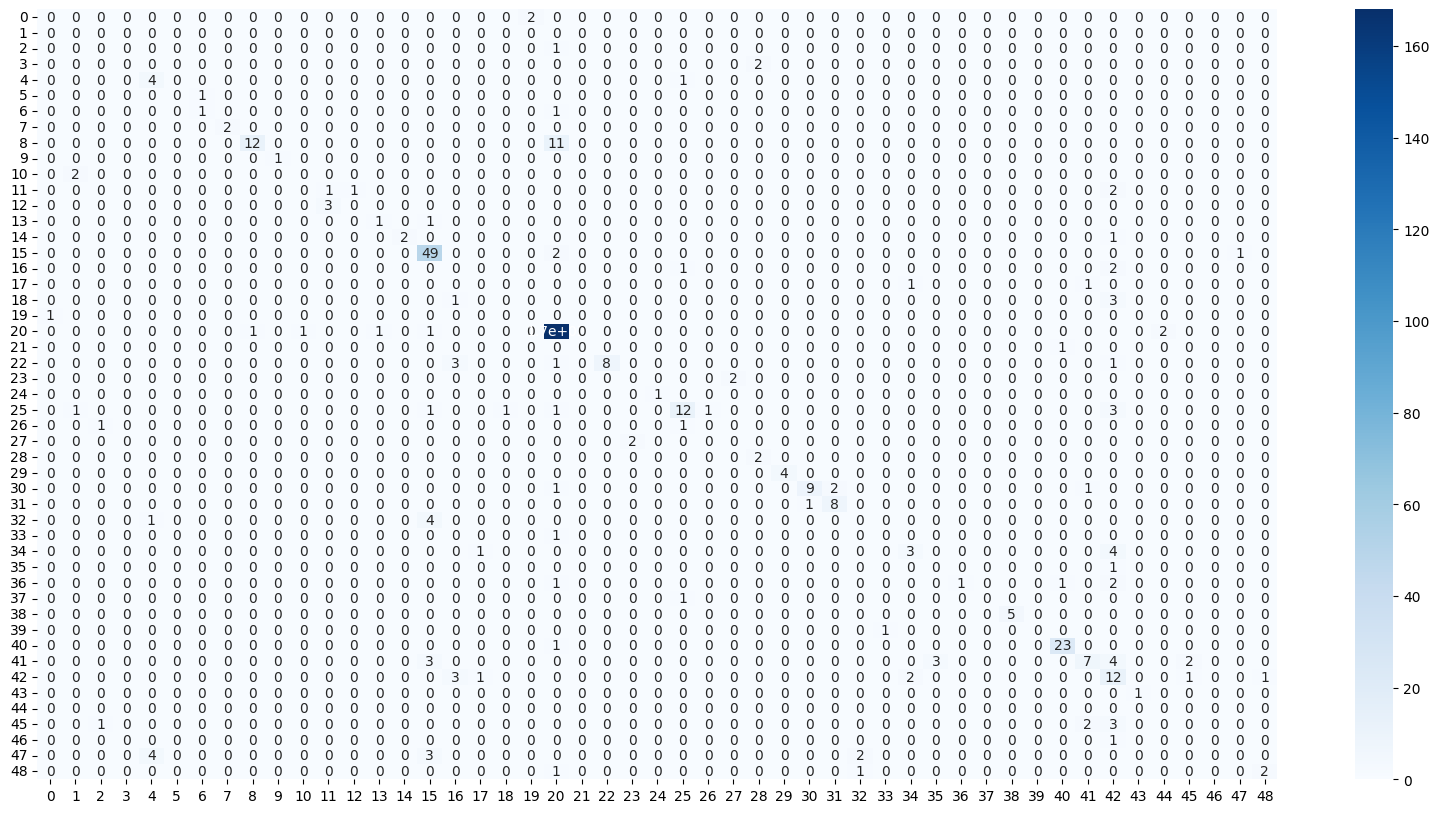

In [22]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(20,10))
sns.heatmap(cm, cmap='Blues', annot=True)
plt.show()

In [24]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.00      0.00      0.00         2
           2       0.00      0.00      0.00         0
           4       0.00      0.00      0.00         1
           5       0.00      0.00      0.00         2
           6       0.44      0.80      0.57         5
           7       0.00      0.00      0.00         1
           8       0.50      0.50      0.50         2
          11       1.00      1.00      1.00         2
          13       0.92      0.52      0.67        23
          14       1.00      1.00      1.00         1
          15       0.00      0.00      0.00         2
          16       0.25      0.25      0.25         4
          17       0.00      0.00      0.00         3
          19       0.50      0.50      0.50         2
          20       1.00      0.67      0.80         3
          21       0.79      0.94      0.86        52
          22       0.00      0.00      0.00         3
          23       0.00    

c:\Users\dipen\OneDrive\Desktop\Qriocity\venv\lib\site-packages\sklearn\metrics\_classification.py:1334: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\dipen\OneDrive\Desktop\Qriocity\venv\lib\site-packages\sklearn\metrics\_classification.py:1334: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\dipen\OneDrive\Desktop\Qriocity\venv\lib\site-packages\sklearn\metrics\_classification.py:1334: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [23]:
import pickle

with open('clf.pkl','wb') as f:
    pickle.dump(clf,f)

with open('features.pkl','wb') as f:
    pickle.dump(selected_features,f)